# **Welcome to my Math project**
In here I will do all the neccassary code for python.

This was writen fully in the "https://colab.research.google.com/" if you want to see it you it will also be attached in the in my REPO under "Extra code"

## **Importing all te nessasary packages**


In [37]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.fft import rfft, rfftfreq
import matplotlib.pyplot as plt

1. Load the data and replace missing values

In [38]:
DATA_PATH = "WarsawNassa_Power_data.csv"
df = pd.read_csv(DATA_PATH, skiprows=13)

In [39]:
df = df.replace(-999, np.nan).dropna().reset_index(drop=True)

2. Construct a proper calendar Date column

In [40]:
df["DATE"] = pd.to_datetime(df["YEAR"].astype(str), format="%Y") + pd.to_timedelta(
    df["DOY"] - 1, unit="D"
)

print(f"Loaded {len(df)} daily observations from {df['DATE'].min().date()} to {df['DATE'].max().date()}.\n")
print("=== DESCRIPTIVE STATISTICS ===")
print(df[["T2M", "ALLSKY_SFC_SW_DWN", "RH2M", "PS", "WS2M"]].describe().round(3))

Loaded 3289 daily observations from 2015-12-31 to 2024-12-31.

=== DESCRIPTIVE STATISTICS ===
            T2M  ALLSKY_SFC_SW_DWN      RH2M        PS      WS2M
count  3289.000           3289.000  3289.000  3289.000  3289.000
mean      9.464             10.914    79.450   100.053     2.951
std       9.040              8.102    13.035     0.849     1.280
min     -17.100              0.440    37.420    96.540     0.470
25%       1.900              3.310    68.900    99.540     2.010
50%       9.210              9.240    80.790   100.070     2.740
75%      17.530             17.670    91.450   100.600     3.670
max      28.560             30.910    99.870   102.920     9.420


# **ANALYSIS 1: MULTIPLE LINEAR REGRESSION (OLS)**

1. construct the foundasion of the model

In [41]:
features = ["ALLSKY_SFC_SW_DWN", "RH2M", "PS", "WS2M"]
target = "T2M"

2. Fit the the OLS model


In [42]:
X_raw = sm.add_constant(df[features])
y_raw = df[target]
model_raw = sm.OLS(y_raw, X_raw).fit()

Summary of the Model thats fitted

In [43]:
print("\n=== ANALYSIS 1: MULTIPLE LINEAR REGRESSION (PHYSICAL UNITS) ===")
print(model_raw.summary())


=== ANALYSIS 1: MULTIPLE LINEAR REGRESSION (PHYSICAL UNITS) ===
                            OLS Regression Results                            
Dep. Variable:                    T2M   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     1352.
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:25:49   Log-Likelihood:                -10307.
No. Observations:                3289   AIC:                         2.062e+04
Df Residuals:                    3284   BIC:                         2.065e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

3. Standardise the OLS model to z-values for better predictions

In [44]:
df_std = (df[features + [target]] - df[features + [target]].mean()) / df[features + [target]].std()
X_std = sm.add_constant(df_std[features])
y_std = df_std[target]
model_std = sm.OLS(y_std, X_std).fit()

Summary of the Model thats fitted

In [45]:
print("\n=== STANDARDIZED REGRESSION COEFFICIENTS (BETA WEIGHTS) ===")
for feat in features:
    coef = model_std.params[feat]
    pval = model_std.pvalues[feat]
    print(f"{feat:20s}: beta_std = {coef:+.4f} (p = {pval:.2e})")


=== STANDARDIZED REGRESSION COEFFICIENTS (BETA WEIGHTS) ===
ALLSKY_SFC_SW_DWN   : beta_std = +0.4522 (p = 8.96e-94)
RH2M                : beta_std = -0.3299 (p = 9.79e-54)
PS                  : beta_std = -0.2130 (p = 1.40e-75)
WS2M                : beta_std = -0.1135 (p = 8.87e-22)


Cheak for monoliniarity if sattisfies assumpsion A4

In [46]:
vif_df = pd.DataFrame({
    "Variable": features,
    "VIF": [variance_inflation_factor(X_raw.values, i + 1) for i in range(len(features))]
})
print("\n=== VARIANCE INFLATION FACTORS (MULTICOLLINEARITY CHECK) ===")
print(vif_df.to_string(index=False))


=== VARIANCE INFLATION FACTORS (MULTICOLLINEARITY CHECK) ===
         Variable      VIF
ALLSKY_SFC_SW_DWN 3.946513
             RH2M 3.829141
               PS 1.105990
             WS2M 1.201563


## **Analysis 2: AST FOURIER TRANSFORM**

1. prepare the data frame for the fourier Transform

In [47]:
solar_signal = df["ALLSKY_SFC_SW_DWN"].values
N = len(solar_signal)
dt = 1.0  # Sampling interval = 1 day

2. Subtract mean (DC component) so zero-frequency spike doesn't mask periodic cycles

In [48]:
solar_centered = solar_signal - np.mean(solar_signal)

3. Compute one-sided Real FFT and Power Spectral Density

In [49]:
fft_vals = rfft(solar_centered)
freqs = rfftfreq(N, d=dt)  # Frequency in cycles/day
psd = (np.abs(fft_vals) ** 2) / N

4. Find dominant frequency peak

In [50]:
peak_idx = np.argmax(psd[1:]) + 1
dominant_freq = freqs[peak_idx]
dominant_period = 1.0 / dominant_freq

Summerise this transformation

In [51]:
print("\n=== ANALYSIS 2: FAST FOURIER TRANSFORM (SOLAR IRRADIANCE) ===")
print(f"Dominant Frequency : {dominant_freq:.6f} cycles/day")
print(f"Dominant Period    : {dominant_period:.2f} days (Earth's orbital cycle)")
print(f"Peak PSD           : {psd[peak_idx]:.2f}")


=== ANALYSIS 2: FAST FOURIER TRANSFORM (SOLAR IRRADIANCE) ===
Dominant Frequency : 0.002736 cycles/day
Dominant Period    : 365.44 days (Earth's orbital cycle)
Peak PSD           : 82708.83


# **Vissualisation 1**

1. of the MLR

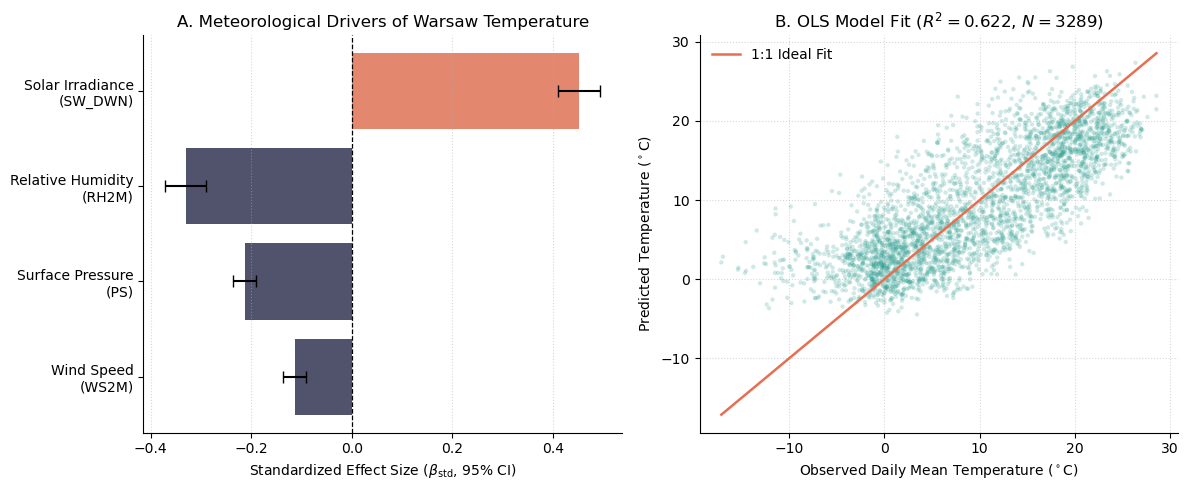

In [ ]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

labels = ["Solar Irradiance\n(SW_DWN)", "Relative Humidity\n(RH2M)", "Surface Pressure\n(PS)", "Wind Speed\n(WS2M)"]
betas = [model_std.params[f] for f in features]
errors = [1.96 * model_std.bse[f] for f in features]
colors = ["#e07a5f" if b > 0 else "#3d405b" for b in betas]

ax1.barh(labels[::-1], betas[::-1], xerr=errors[::-1], color=colors[::-1], capsize=4, alpha=0.9)
ax1.axvline(0, color="black", linewidth=0.9, linestyle="--")
ax1.set_xlabel("Standardized Effect Size ($\\beta_{\\mathrm{std}}$, 95% CI)")
ax1.set_title("A. Meteorological Drivers of Warsaw Temperature")
ax1.grid(axis="x", linestyle=":", alpha=0.5)

y_pred = model_raw.predict(X_raw)
ax2.scatter(y_raw, y_pred, alpha=0.22, s=10, color="#2a9d8f", edgecolors="none")
min_val, max_val = min(y_raw.min(), y_pred.min()), max(y_raw.max(), y_pred.max())
ax2.plot([min_val, max_val], [min_val, max_val], color="#e76f51", linewidth=1.8, label="1:1 Ideal Fit")
ax2.set_xlabel("Observed Daily Mean Temperature ($^\\circ$C)")
ax2.set_ylabel("Predicted Temperature ($^\\circ$C)")
ax2.set_title(f"B. OLS Model Fit ($R^2 = {model_raw.rsquared:.3f}$, $N = {N}$)")
ax2.legend(frameon=False)
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("fft_solar_spectrum.pdf", format="pdf", bbox_inches="tight")
plt.show()

2. of the Furier

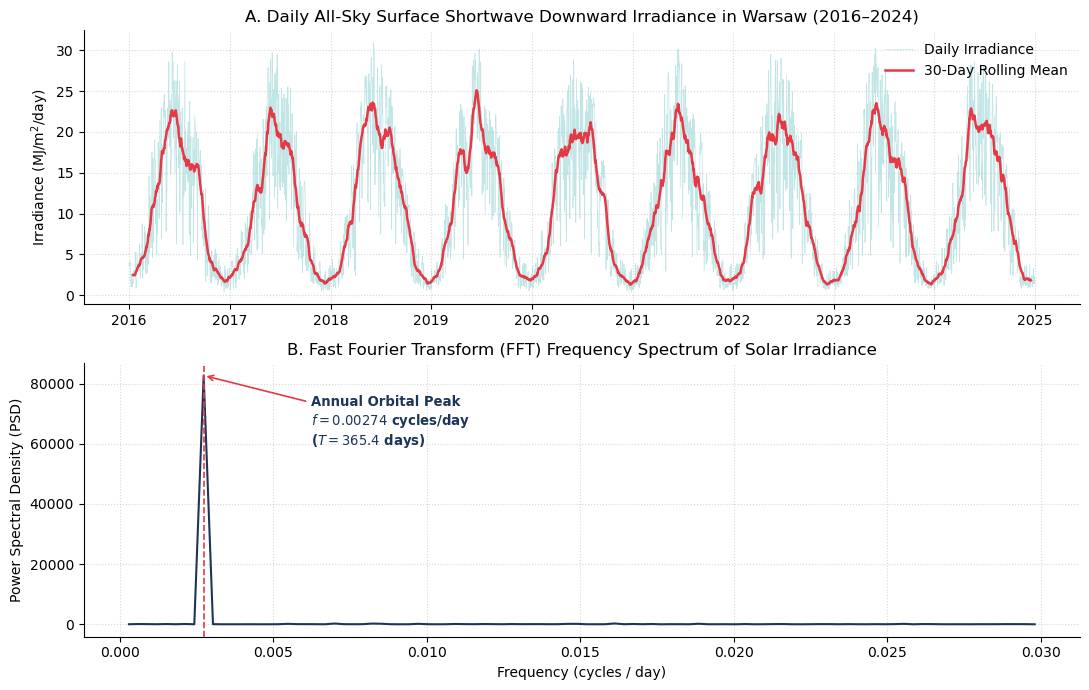

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))

rolling_30d = df["ALLSKY_SFC_SW_DWN"].rolling(window=30, center=True).mean()
ax1.plot(df["DATE"], df["ALLSKY_SFC_SW_DWN"], color="#a8dadc", linewidth=0.5, alpha=0.7, label="Daily Irradiance")
ax1.plot(df["DATE"], rolling_30d, color="#e63946", linewidth=1.8, label="30-Day Rolling Mean")
ax1.set_ylabel("Irradiance (MJ/m$^2$/day)")
ax1.set_title("A. Daily All-Sky Surface Shortwave Downward Irradiance in Warsaw (2016–2024)")
ax1.legend(loc="upper right", frameon=False)
ax1.grid(True, linestyle=":", alpha=0.5)

mask = (freqs > 0) & (freqs <= 0.03)
ax2.plot(freqs[mask], psd[mask], color="#1d3557", linewidth=1.5)
ax2.axvline(dominant_freq, color="#e63946", linestyle="--", linewidth=1.2)
ax2.annotate(
    f"Annual Orbital Peak\n$f = {dominant_freq:.5f}$ cycles/day\n($T = {dominant_period:.1f}$ days)",
    xy=(dominant_freq, psd[peak_idx]),
    xytext=(dominant_freq + 0.0035, psd[peak_idx] * 0.72),
    arrowprops=dict(arrowstyle="->", color="#e63946", lw=1.2),
    fontsize=9.5,
    fontweight="bold",
    color="#1d3557"
)
ax2.set_xlabel("Frequency (cycles / day)")
ax2.set_ylabel("Power Spectral Density (PSD)")
ax2.set_title("B. Fast Fourier Transform (FFT) Frequency Spectrum of Solar Irradiance")
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("regression_analysis.pdf", format="pdf", bbox_inches="tight")
plt.show()